# Praproses Data dan Model Awal Decision Tree

Notebook ini mengerjakan tahap praproses awal dan pembangunan model awal (*baseline*) untuk studi kasus *Credit Scoring* menggunakan berkas `cs-training.csv` dari dataset Give Me Some Credit.

Ruang lingkup pengerjaan pada tahap ini:
1. Memuat `cs-training.csv`, memisahkan kolom target `SeriousDlqin2yrs`, dan mengeluarkan kolom indeks `Unnamed: 0` dari fitur.
2. Membagi data menjadi 80% data latih dan 20% data uji akhir menggunakan *stratified split* dengan `random_state=42`.
3. Mengisi nilai kosong pada `MonthlyIncome` dan `NumberOfDependents` menggunakan median yang dihitung dari bagian data latih melalui `Pipeline`.
4. Menetapkan Decision Tree dengan `max_depth=5` dan bobot kelas bawaan sebagai model awal, mengevaluasinya lewat validasi silang 5-fold (*Stratified K-Fold*) pada 80% data latih, serta menyimpan hasil `DummyClassifier`, variasi kedalaman pohon, dan `class_weight="balanced"` sebagai pembanding. Bagian 20% data uji hanya diperiksa jumlah baris, proporsi kelas, dan nilai kosongnya lalu ditransformasi memakai median dari data latih; data uji tersebut belum dipakai untuk memilih model maupun menghitung metrik evaluasi.

## 1. Pemuatan Data dan Pemeriksaan Struktur

Kita mulai dengan menyiapkan pustaka yang dibutuhkan dan memuat `cs-training.csv` dari folder `data/`. Pemeriksaan awal dilakukan untuk memastikan jumlah baris, nama kolom, serta tipe data sesuai dengan deskripsi dataset.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    confusion_matrix,
    make_scorer,
    precision_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

RANDOM_STATE = 42
TARGET_COL = "SeriousDlqin2yrs"
INDEX_COL = "Unnamed: 0"

# Cari folder data/ baik ketika notebook dijalankan dari root repo maupun dari folder notebooks/
candidate_paths = [Path("data/cs-training.csv"), Path("../data/cs-training.csv")]
data_path = next((p for p in candidate_paths if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Berkas data/cs-training.csv tidak ditemukan.")

df = pd.read_csv(data_path)

print(f"Lokasi berkas : {data_path}")
print(f"Ukuran data   : {df.shape[0]:,} baris x {df.shape[1]} kolom")
print("\nDaftar kolom:")
for i, col in enumerate(df.columns, start=1):
    print(f"  {i:2d}. {col} ({df[col].dtype})")

Lokasi berkas : ..\data\cs-training.csv
Ukuran data   : 150,000 baris x 12 kolom

Daftar kolom:
   1. Unnamed: 0 (int64)
   2. SeriousDlqin2yrs (int64)
   3. RevolvingUtilizationOfUnsecuredLines (float64)
   4. age (int64)
   5. NumberOfTime30-59DaysPastDueNotWorse (int64)
   6. DebtRatio (float64)
   7. MonthlyIncome (float64)
   8. NumberOfOpenCreditLinesAndLoans (int64)
   9. NumberOfTimes90DaysLate (int64)
  10. NumberRealEstateLoansOrLines (int64)
  11. NumberOfTime60-89DaysPastDueNotWorse (int64)
  12. NumberOfDependents (float64)


### Analisis Struktur Data

Berkas `cs-training.csv` berisi `150.000` baris dan `12` kolom bertipe numerik (`int64` dan `float64`). Selain `Unnamed: 0` (nomor urut baris dari berkas CSV) dan `SeriousDlqin2yrs` (kolom target biner), terdapat `10` fitur utama yang terbagi ke dalam tiga kategori informasi peminjam:

| Jenis informasi | Kolom |
| --- | --- |
| Profil peminjam | `age`, `MonthlyIncome`, `NumberOfDependents` |
| Penggunaan kredit dan pinjaman | `RevolvingUtilizationOfUnsecuredLines`, `DebtRatio`, `NumberOfOpenCreditLinesAndLoans`, `NumberRealEstateLoansOrLines` |
| Riwayat keterlambatan | `NumberOfTime30-59DaysPastDueNotWorse`, `NumberOfTime60-89DaysPastDueNotWorse`, `NumberOfTimes90DaysLate` |

Target `SeriousDlqin2yrs` mencatat apakah peminjam mengalami tunggakan serius selama 90 hari atau lebih dalam dua tahun setelah profilnya dicatat (`1` = mengalami tunggakan serius, `0` = tidak mengalami tunggakan sampai 90 hari).

## 2. Pemeriksaan Distribusi Target, Nilai Kosong, dan Anomali Awal

Sebelum membagi data, kita memeriksa komposisi kelas target, pola nilai kosong, serta sebaran nilai ekstrem pada fitur agar keputusan praproses dan pemilihan metrik evaluasi sesuai dengan kondisi data sebenarnya.

Distribusi kolom target (SeriousDlqin2yrs):


,jumlah_baris,persentase (%)
SeriousDlqin2yrs,,
0,139974,93.32
1,10026,6.68



Kolom yang memiliki nilai kosong:


,jumlah_kosong,persentase (%)
MonthlyIncome,29731,19.82
NumberOfDependents,3924,2.62


Baris kosong di keduanya         : 3,924
Kosong di NumberOfDependents saja: 0


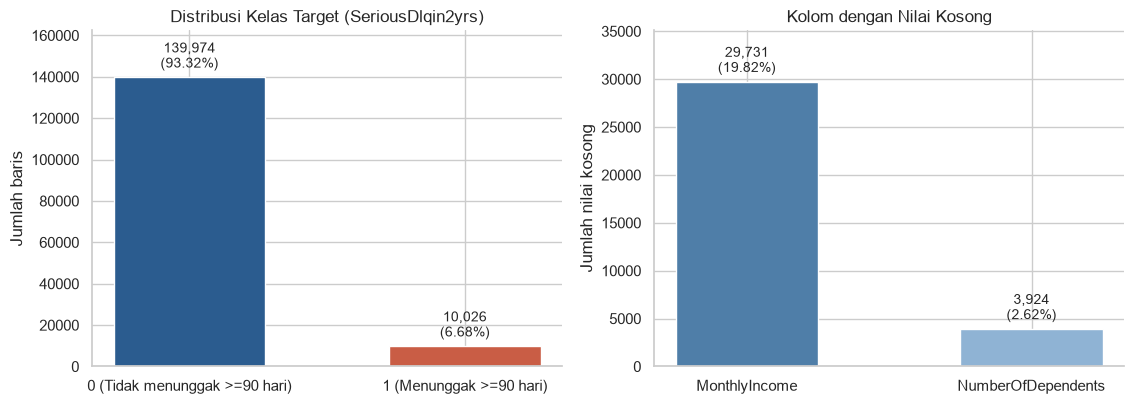

In [2]:
target_counts = df[TARGET_COL].value_counts().sort_index()
target_pct = df[TARGET_COL].value_counts(normalize=True).sort_index() * 100
target_summary = pd.DataFrame({
    "jumlah_baris": target_counts,
    "persentase (%)": target_pct.round(2),
})
print("Distribusi kolom target (SeriousDlqin2yrs):")
display(target_summary)

missing_df = pd.DataFrame({
    "jumlah_kosong": df.isna().sum(),
    "persentase (%)": (df.isna().mean() * 100).round(2),
})
missing_only = missing_df[missing_df["jumlah_kosong"] > 0]
print("\nKolom yang memiliki nilai kosong:")
display(missing_only)

both_missing = (df["MonthlyIncome"].isna() & df["NumberOfDependents"].isna()).sum()
dep_only_missing = (df["MonthlyIncome"].notna() & df["NumberOfDependents"].isna()).sum()
print(f"Baris kosong di keduanya         : {both_missing:,}")
print(f"Kosong di NumberOfDependents saja: {dep_only_missing:,}")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))

colors_target = ["#2b5c8f", "#c95d45"]
bars = axes[0].bar(
    ["0 (Tidak menunggak >=90 hari)", "1 (Menunggak >=90 hari)"],
    target_counts.values,
    color=colors_target,
    width=0.55,
)
axes[0].set_title("Distribusi Kelas Target (SeriousDlqin2yrs)")
axes[0].set_ylabel("Jumlah baris")
axes[0].set_ylim(0, target_counts.max() * 1.16)
for bar, count, pct in zip(bars, target_counts.values, target_pct.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2500,
        f"{count:,}\n({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
    )

bars_na = axes[1].bar(
    missing_only.index,
    missing_only["jumlah_kosong"].values,
    color=["#4f7ea8", "#8fb3d4"],
    width=0.5,
)
axes[1].set_title("Kolom dengan Nilai Kosong")
axes[1].set_ylabel("Jumlah nilai kosong")
axes[1].set_ylim(0, missing_only["jumlah_kosong"].max() * 1.18)
for bar, count, pct in zip(
    bars_na,
    missing_only["jumlah_kosong"].values,
    missing_only["persentase (%)"].values,
):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 600,
        f"{count:,}\n({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
    )

plt.tight_layout()
plt.show()

### Analisis Target dan Nilai Kosong

Hasil pengecekan mengonfirmasi dua kondisi penting pada dataset:
1. Proporsi kelas target sangat tidak seimbang. Dari `150.000` baris, kelas `0` berjumlah `139.974` baris (`93,32%`) sedangkan kelas `1` hanya `10.026` baris (`6,68%`), atau perbandingan sekitar 14 banding 1. Konsekuensinya, pembagian data harus mempertahankan proporsi kelas (*stratified*), dan evaluasi model tidak boleh bertumpu pada akurasi semata.
2. Nilai kosong hanya muncul pada dua fitur, yaitu `MonthlyIncome` sebanyak `29.731` baris (`19,82%`) dan `NumberOfDependents` sebanyak `3.924` baris (`2,62%`). Seluruh `3.924` baris yang kosong pada `NumberOfDependents` juga kosong pada `MonthlyIncome` (`0` baris yang hanya kosong di tanggungan). Kolom target dan delapan fitur lainnya terisi penuh.

Selanjutnya kita periksa ringkasan statistik deskriptif dan beberapa nilai yang patut dicatat sebagai anomali awal.

In [3]:
feature_cols = [c for c in df.columns if c not in (INDEX_COL, TARGET_COL)]
display(df[feature_cols].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).T.round(2))

late_cols = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
]
anomaly_summary = pd.DataFrame([
    {"pemeriksaan": "Baris duplikat (mengabaikan Unnamed: 0)", "jumlah_baris": int(df.drop(columns=[INDEX_COL]).duplicated().sum())},
    {"pemeriksaan": "age == 0", "jumlah_baris": int((df["age"] == 0).sum())},
    {"pemeriksaan": "Kode 96 pada kolom keterlambatan", "jumlah_baris": int((df[late_cols[0]] == 96).sum())},
    {"pemeriksaan": "Kode 98 pada kolom keterlambatan", "jumlah_baris": int((df[late_cols[0]] == 98).sum())},
    {"pemeriksaan": "MonthlyIncome == 0 (terisi nol, bukan kosong)", "jumlah_baris": int((df["MonthlyIncome"] == 0).sum())},
])
print("Ringkasan catatan kualitas data:")
display(anomaly_summary)

income_na_check = df.groupby(df["MonthlyIncome"].isna()).agg(
    jumlah_baris=(TARGET_COL, "count"),
    rasio_gagal_bayar=(TARGET_COL, "mean"),
    median_debt_ratio=("DebtRatio", "median"),
)
income_na_check.index = ["MonthlyIncome terisi", "MonthlyIncome kosong"]
income_na_check["rasio_gagal_bayar"] = (income_na_check["rasio_gagal_bayar"] * 100).round(2)
income_na_check = income_na_check.rename(columns={"rasio_gagal_bayar": "rasio_gagal_bayar (%)"})
print("\nPerbandingan perilaku data saat MonthlyIncome terisi vs kosong:")
display(income_na_check)

,count,mean,std,min,25%,50%,75%,99%,max
RevolvingUtilizationOfUnsecuredLines,150000.0,6.05,249.76,0.0,0.03,0.15,0.56,1.09,50708.0
age,150000.0,52.30,14.77,0.0,41.00,52.00,63.00,87.00,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.42,4.19,0.0,0.00,0.00,0.00,4.00,98.0
DebtRatio,150000.0,353.01,2037.82,0.0,0.18,0.37,0.87,4979.04,329664.0
MonthlyIncome,120269.0,6670.22,14384.67,0.0,3400.00,5400.00,8249.00,25000.00,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.45,5.15,0.0,5.00,8.00,11.00,24.00,58.0
NumberOfTimes90DaysLate,150000.0,0.27,4.17,0.0,0.00,0.00,0.00,3.00,98.0
NumberRealEstateLoansOrLines,150000.0,1.02,1.13,0.0,0.00,1.00,2.00,4.00,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.24,4.16,0.0,0.00,0.00,0.00,2.00,98.0
NumberOfDependents,146076.0,0.76,1.12,0.0,0.00,0.00,1.00,4.00,20.0


Ringkasan catatan kualitas data:


,pemeriksaan,jumlah_baris
0,Baris duplikat (mengabaikan Unnamed: 0),609
1,age == 0,1
2,Kode 96 pada kolom keterlambatan,5
3,Kode 98 pada kolom keterlambatan,264
4,"MonthlyIncome == 0 (terisi nol, bukan kosong)",1634



Perbandingan perilaku data saat MonthlyIncome terisi vs kosong:


,jumlah_baris,rasio_gagal_bayar (%),median_debt_ratio
MonthlyIncome terisi,120269,6.95,0.296023
MonthlyIncome kosong,29731,5.61,1159.000000


### Catatan Anomali untuk Tahap Lanjutan

Dari ringkasan statistik di atas, ada beberapa temuan yang berguna untuk iterasi pemodelan selanjutnya:
- Nilai `age == 0` muncul pada `1` baris, sementara umur minimum yang wajar untuk peminjam dewasa berada di atas 20 tahun.
- Nilai `96` (`5` baris) dan `98` (`264` baris) muncul secara seragam pada ketiga kolom riwayat keterlambatan. Pola ini lazim menandakan kode khusus pencatatan (misalnya penolakan informasi), bukan jumlah keterlambatan sebenarnya.
- Terdapat `609` baris dengan seluruh nilai fitur dan target yang identik ketika `Unnamed: 0` diabaikan.
- Ketika `MonthlyIncome` kosong, median `DebtRatio` melonjak menjadi `1.159,00` dibanding `0,30` saat `MonthlyIncome` terisi, sementara rasio gagal bayarnya sedikit lebih rendah (`5,61%` dibanding `6,95%`). Saat pendapatan tidak tercatat, kolom `DebtRatio` cenderung berisi total kewajiban bulanan mentah alih-alih rasio terhadap pendapatan.

Pada notebook model awal ini, kita sengaja belum menghapus baris anomali maupun menambah fitur baru agar baseline tetap bersih mengikuti praproses sederhana (hapus `Unnamed: 0`, split 80:20, dan imputasi median). Temuan ini dicatat sebagai acuan langsung untuk eksperimen rekayasa fitur pada tahap berikutnya.

## 3. Pemisahan Target, Penghapusan `Unnamed: 0`, dan Stratified Split 80:20

Kolom `Unnamed: 0` hanya berisi nomor urut baris dari berkas asli sehingga harus dikeluarkan agar model tidak belajar dari urutan penyimpanan data. Setelah memisahkan fitur `X` dan target `y`, data dibagi `80%` untuk pelatihan (`X_train`, `y_train`) dan `20%` untuk pengujian akhir (`X_test`, `y_test`) secara *stratified* dengan `random_state=42`.

Bagian `20%` hanya diperiksa jumlah baris, proporsi label, dan nilai kosongnya lalu ditransformasi memakai median dari data latih pada bagian berikutnya. Data uji tersebut belum dipakai untuk memilih model, menyetel parameter, maupun menghitung metrik evaluasi pada notebook ini.

In [4]:
y = df[TARGET_COL].copy()
X = df.drop(columns=[INDEX_COL, TARGET_COL]).copy()

assert INDEX_COL not in X.columns, "Kolom Unnamed: 0 masih ada di fitur."
assert TARGET_COL not in X.columns, "Kolom target masih ada di fitur."
assert X.shape == (150000, 10), f"Dimensi fitur tidak sesuai: {X.shape}"

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)

split_summary = pd.DataFrame([
    {
        "bagian": "Data penuh (100%)",
        "jumlah_baris": len(y),
        "label_0": int((y == 0).sum()),
        "label_1": int((y == 1).sum()),
        "proporsi_label_1 (%)": round(y.mean() * 100, 4),
    },
    {
        "bagian": "Data latih (80%)",
        "jumlah_baris": len(y_train),
        "label_0": int((y_train == 0).sum()),
        "label_1": int((y_train == 1).sum()),
        "proporsi_label_1 (%)": round(y_train.mean() * 100, 4),
    },
    {
        "bagian": "Data uji akhir (20%, disisihkan)",
        "jumlah_baris": len(y_test),
        "label_0": int((y_test == 0).sum()),
        "label_1": int((y_test == 1).sum()),
        "proporsi_label_1 (%)": round(y_test.mean() * 100, 4),
    },
])
display(split_summary)

,bagian,jumlah_baris,label_0,label_1,proporsi_label_1 (%)
0,Data penuh (100%),150000,139974,10026,6.6840
1,Data latih (80%),120000,111979,8021,6.6842
2,"Data uji akhir (20%, disisihkan)",30000,27995,2005,6.6833


### Verifikasi Hasil Pembagian Data

Pemisahan berjalan sesuai target:
- `X` kini hanya berisi `10` kolom fitur tanpa `Unnamed: 0` dan tanpa kolom target.
- Data latih (`80%`) terdiri dari `120.000` baris dengan `8.021` kasus label `1` (`6,6842%`) dan `111.979` kasus label `0`.
- Data uji akhir (`20%`) terdiri dari `30.000` baris dengan `2.005` kasus label `1` (`6,6833%`) dan `27.995` kasus label `0`.

Penggunaan `stratify=y` menjaga proporsi kelas minoritas identik hingga dua angka di belakang koma (`6,68%`), dan `random_state=42` memastikan anggota tim lain mendapatkan susunan pembagian yang persis sama saat menjalankan ulang notebook ini.

## 4. Imputasi Nilai Kosong dengan Median dari Data Latih

Nilai kosong pada `MonthlyIncome` dan `NumberOfDependents` diisi dengan median. Nilai median dihitung hanya dari bagian data yang dipakai untuk melatih model, lalu nilai yang sama diterapkan pada data validasi maupun data uji agar tidak terjadi kebocoran data (*data leakage*).

Catatan: di dalam `Pipeline`, `SimpleImputer(strategy="median")` dipasang pada seluruh 10 kolom fitur, namun nilai kosong yang benar-benar terisi hanya ada pada `MonthlyIncome` dan `NumberOfDependents` karena delapan kolom fitur lainnya sudah terisi lengkap (`0` nilai kosong).

In [5]:
median_imputer = SimpleImputer(strategy="median")

# Fit imputer hanya pada X_train, lalu terapkan hasil yang sama ke X_train dan X_test
X_train_imputed = pd.DataFrame(
    median_imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index,
)
X_test_imputed = pd.DataFrame(
    median_imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index,
)

cols_with_na = [c for c in X_train.columns if X_train[c].isna().any() or X_test[c].isna().any()]
assert cols_with_na == ["MonthlyIncome", "NumberOfDependents"]

median_table = pd.DataFrame({
    "kolom_terisi": cols_with_na,
    "kosong_di_train": [int(X_train[c].isna().sum()) for c in cols_with_na],
    "kosong_di_test": [int(X_test[c].isna().sum()) for c in cols_with_na],
    "median_X_train (dipakai)": [
        float(median_imputer.statistics_[X_train.columns.get_loc(c)]) for c in cols_with_na
    ],
    "median_data_penuh (pembanding)": [float(X[c].median()) for c in cols_with_na],
})
display(median_table)

# Pastikan delapan kolom lain tidak memiliki nilai kosong yang berubah
other_cols = [c for c in X_train.columns if c not in cols_with_na]
assert (X_train[other_cols].isna().sum().sum() == 0) and (X_test[other_cols].isna().sum().sum() == 0)
assert X_train_imputed.isna().sum().sum() == 0
assert X_test_imputed.isna().sum().sum() == 0

print("Kolom yang benar-benar terisi oleh imputer:", ", ".join(cols_with_na))
print(f"Total nilai kosong di 8 fitur lainnya (train/test): 0 / 0")
print(f"Total nilai kosong setelah imputasi (X_train/X_test): {X_train_imputed.isna().sum().sum()} / {X_test_imputed.isna().sum().sum()}")

,kolom_terisi,kosong_di_train,kosong_di_test,median_X_train (dipakai),median_data_penuh (pembanding)
0,MonthlyIncome,23675,6056,5390.0,5400.0
1,NumberOfDependents,3128,796,0.0,0.0


Kolom yang benar-benar terisi oleh imputer: MonthlyIncome, NumberOfDependents
Total nilai kosong di 8 fitur lainnya (train/test): 0 / 0
Total nilai kosong setelah imputasi (X_train/X_test): 0 / 0


### Analisis Hasil Imputasi Median

Pemeriksaan di atas memastikan dua hal penting:
- Nilai kosong yang terisi oleh `SimpleImputer(strategy="median")` hanya berada di `MonthlyIncome` (`23.675` baris di `X_train` dan `6.056` baris di `X_test`) dan `NumberOfDependents` (`3.128` baris di `X_train` dan `796` baris di `X_test`). Delapan fitur lainnya tidak memiliki nilai kosong sehingga nilainya tidak berubah.
- Median `MonthlyIncome` pada `X_train` (80%) adalah `5.390,0`, berbeda dari median jika dihitung pada seluruh 150.000 baris (`5.400,0`). Perbedaan ini menunjukkan secara nyata mengapa median tidak boleh dihitung sebelum *split*. Sementara itu, median `NumberOfDependents` pada `X_train` adalah `0,0`, sesuai dengan mayoritas peminjam yang tidak memiliki tanggungan.

Pada langkah ini, data uji 20% (`X_test`) hanya dicek jumlah nilai kosongnya lalu ditransformasi memakai median dari `X_train` untuk memastikan tidak ada nilai kosong yang tersisa, tanpa dipakai untuk memilih model maupun menghitung metrik evaluasi. Pada tahap validasi silang berikutnya, `SimpleImputer(strategy="median")` dibungkus ke dalam `Pipeline` scikit-learn sehingga median selalu dihitung ulang hanya dari fold pelatihan pada setiap iterasi fold.

## 5. Model Awal Decision Tree dan Pembanding pada Validasi 5-Fold (80% Data Latih)

Seluruh evaluasi dilakukan pada `X_train` dan `y_train` (`120.000` baris) menggunakan **5-Fold Stratified Cross-Validation**. Setiap fold melatih `Pipeline` (imputasi median + model) pada `96.000` baris dan memvalidasinya pada `24.000` baris. Data uji akhir (`30.000` baris) belum dipakai untuk memilih model maupun menghitung metrik pada seluruh tahap ini.

Model awal yang ditetapkan pada tahap ini adalah **Decision Tree dengan `max_depth=5` (`min_samples_leaf=50`) dan bobot kelas bawaan**. Sebagai pembanding, kita juga menyimpan hasil variasi kedalaman pohon, `DummyClassifier`, serta versi `class_weight="balanced"`.

### 5.1 Pembanding Variasi Kedalaman Pohon (`max_depth`)

Pengujian variasi `max_depth` dilakukan untuk melihat titik transisi antara *underfitting* dan *overfitting* serta menjadi dasar pemilihan `max_depth=5` pada model awal.

,max_depth,min_samples_leaf,train_roc_auc,val_roc_auc,val_std,selisih_train_val
0,2,50,0.7772,0.7764,0.0047,0.0008
1,3,50,0.8034,0.8012,0.0054,0.0022
2,4,50,0.8279,0.8272,0.0043,0.0008
3,5,50,0.8456,0.8437,0.0037,0.0018
4,6,50,0.8508,0.8468,0.0032,0.0040
5,7,50,0.8579,0.8503,0.0034,0.0077
6,8,50,0.8629,0.8509,0.0034,0.0120
7,10,50,0.8740,0.8460,0.0038,0.0280
8,12,50,0.8859,0.8374,0.0058,0.0485
9,None (tanpa batas),1,1.0000,0.6120,0.0020,0.3880


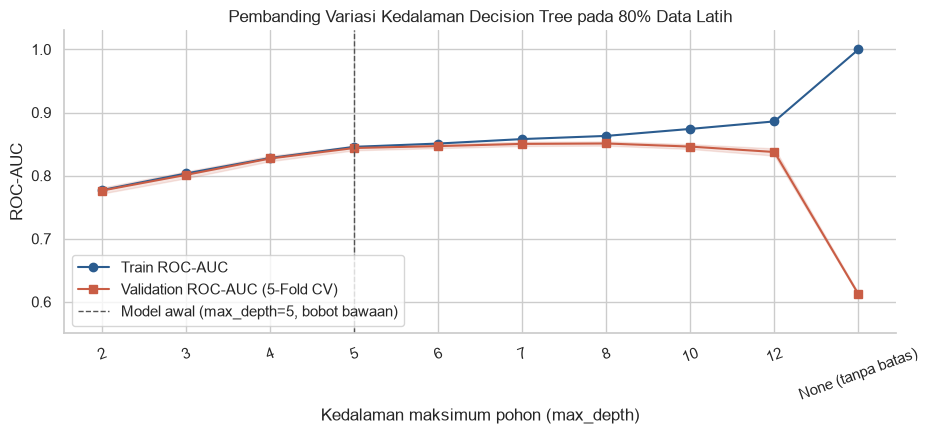

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

depths = [2, 3, 4, 5, 6, 7, 8, 10, 12, None]
depth_rows = []

for d in depths:
    leaf = 1 if d is None else 50
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(
            max_depth=d,
            min_samples_leaf=leaf,
            random_state=RANDOM_STATE,
        )),
    ])
    res = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc",
        return_train_score=True,
    )
    depth_rows.append({
        "max_depth": "None (tanpa batas)" if d is None else str(d),
        "min_samples_leaf": leaf,
        "train_roc_auc": res["train_score"].mean(),
        "val_roc_auc": res["test_score"].mean(),
        "val_std": res["test_score"].std(),
        "selisih_train_val": res["train_score"].mean() - res["test_score"].mean(),
    })

depth_df = pd.DataFrame(depth_rows)
display(depth_df.round(4))

fig, ax = plt.subplots(figsize=(9.5, 4.5))
x_pos = np.arange(len(depth_df))
ax.plot(x_pos, depth_df["train_roc_auc"], marker="o", color="#2b5c8f", label="Train ROC-AUC")
ax.plot(x_pos, depth_df["val_roc_auc"], marker="s", color="#c95d45", label="Validation ROC-AUC (5-Fold CV)")
ax.fill_between(
    x_pos,
    depth_df["val_roc_auc"] - depth_df["val_std"],
    depth_df["val_roc_auc"] + depth_df["val_std"],
    color="#c95d45",
    alpha=0.15,
)
ax.axvline(x=3, color="#555555", linestyle="--", linewidth=1, label="Model awal (max_depth=5, bobot bawaan)")
ax.set_xticks(x_pos)
ax.set_xticklabels(depth_df["max_depth"], rotation=20)
ax.set_xlabel("Kedalaman maksimum pohon (max_depth)")
ax.set_ylabel("ROC-AUC")
ax.set_title("Pembanding Variasi Kedalaman Decision Tree pada 80% Data Latih")
ax.set_ylim(0.55, 1.03)
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

### Analisis Variasi Kedalaman Pohon

Hasil uji kedalaman memperlihatkan mengapa `max_depth=5` tepat dijadikan model awal:
- Pada `max_depth=2` dan `max_depth=3`, pohon terlalu dangkal sehingga masih *underfit* (Val ROC-AUC `0,7764` dan `0,8012`).
- Pada `max_depth=5` dengan `min_samples_leaf=50`, Val ROC-AUC naik cukup besar ke `0,8437` dengan selisih terhadap Train ROC-AUC (`0,8456`) hanya `0,0019` dan variasi antar fold kecil (`std = 0,0037`).
- Menambah kedalaman hingga `7` atau `8` hanya menambah Val ROC-AUC tipis (puncak `0,8509` di kedalaman 8) sambil mulai melebarkan jarak train-validasi (`0,0120`), lalu skor validasi turun pada kedalaman `10` (`0,8460`) dan `12` (`0,8374`).
- Pohon tanpa batas (`max_depth=None`, `min_samples_leaf=1`) mengalami *overfitting* berat: Train ROC-AUC mencapai `1,0000`, tetapi Val ROC-AUC jatuh ke `0,6120`.

### 5.2 Evaluasi Model Awal vs Pembanding pada 5-Fold Stratified CV

Berikut perbandingan metrik lengkap antara **model awal** (Decision Tree `max_depth=5`, `min_samples_leaf=50`, bobot bawaan) dan tiga **pembanding** (`DummyClassifier`, Decision Tree tanpa batas kedalaman, dan Decision Tree `max_depth=5` dengan `class_weight="balanced"`). Precision dan Recall ditampilkan berdampingan agar terlihat jelas hubungan antara jumlah kasus tunggakan yang tertangkap dan ketepatan peringatan yang dikeluarkan model.

In [7]:
# zero_division=0 mencegah peringatan pada DummyClassifier yang tidak pernah memprediksi kelas 1
scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
    "f1": "f1",
}

model_specs = [
    (
        "Model awal",
        "Decision Tree (max_depth=5, leaf=50, bobot bawaan)",
        DecisionTreeClassifier(max_depth=5, min_samples_leaf=50, random_state=RANDOM_STATE),
    ),
    (
        "Pembanding",
        "DummyClassifier (selalu prediksi 0)",
        DummyClassifier(strategy="most_frequent"),
    ),
    (
        "Pembanding",
        "Decision Tree tanpa batas (max_depth=None)",
        DecisionTreeClassifier(random_state=RANDOM_STATE),
    ),
    (
        "Pembanding",
        "Decision Tree (max_depth=5, leaf=50, class_weight='balanced')",
        DecisionTreeClassifier(
            max_depth=5,
            min_samples_leaf=50,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        ),
    ),
]

cv_rows = []
for role, name, clf in model_specs:
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", clf),
    ])
    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
    )
    cv_rows.append({
        "Peran": role,
        "Model": name,
        "Train ROC-AUC": scores["train_roc_auc"].mean(),
        "Val ROC-AUC": scores["test_roc_auc"].mean(),
        "Std ROC-AUC": scores["test_roc_auc"].std(),
        "Val PR-AUC": scores["test_pr_auc"].mean(),
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision (1)": scores["test_precision"].mean(),
        "Recall (1)": scores["test_recall"].mean(),
        "F1-Score (1)": scores["test_f1"].mean(),
    })

cv_results_df = pd.DataFrame(cv_rows)
display(cv_results_df.round(4))

,Peran,Model,Train ROC-AUC,Val ROC-AUC,Std ROC-AUC,Val PR-AUC,Accuracy,Precision (1),Recall (1),F1-Score (1)
0,Model awal,"Decision Tree (max_depth=5, leaf=50, bobot baw...",0.8456,0.8437,0.0037,0.3529,0.9358,0.5727,0.1628,0.2507
1,Pembanding,DummyClassifier (selalu prediksi 0),0.5000,0.5000,0.0000,0.0668,0.9332,0.0000,0.0000,0.0000
2,Pembanding,Decision Tree tanpa batas (max_depth=None),1.0000,0.6120,0.0020,0.1200,0.8966,0.2537,0.2816,0.2670
3,Pembanding,"Decision Tree (max_depth=5, leaf=50, class_wei...",0.8464,0.8441,0.0035,0.3500,0.7628,0.1907,0.7847,0.3068


### Analisis Perbandingan Model Awal dan Pembanding

Hasil validasi silang 5-fold pada `120.000` baris data latih menunjukkan posisi masing-masing model secara jelas:
1. Model awal Decision Tree (`max_depth=5`, `min_samples_leaf=50`, bobot bawaan) menghasilkan Val ROC-AUC `0,8437` (± `0,0037`) dan PR-AUC `0,3529` tanpa gejala overfitting (`Train ROC-AUC = 0,8456`). Pada ambang bawaan `0,5`, Precision-nya cukup tinggi (`57,27%`), namun Recall-nya masih rendah (`16,28%`) karena kelas minoritas hanya `6,68%`.
2. Pembanding `DummyClassifier` memperoleh Accuracy `93,32%` hanya dengan menebak `0` di semua baris, tetapi ROC-AUC bernilai `0,5000` serta Precision dan Recall kelas `1` sama-sama `0,0000`. Ini membuktikan akurasi tidak cukup untuk mengevaluasi data yang sangat timpang.
3. Pembanding Decision Tree tanpa batas (`max_depth=None`) mengalami overfitting parah (Train ROC-AUC `1,0000`, Val ROC-AUC turun ke `0,6120`, PR-AUC `0,1200`), jauh di bawah model awal.
4. Pembanding `class_weight="balanced"` (`max_depth=5`, `min_samples_leaf=50`) memiliki kualitas pemeringkatan risiko yang hampir identik dengan model awal (Val ROC-AUC `0,8441` ± `0,0035`, PR-AUC `0,3500`), tetapi menggeser keputusan biner secara tajam: Recall melonjak ke `78,47%` (F1-Score `30,68%`), sementara Precision turun ke `19,07%`.

## 6. Confusion Matrix serta Perbandingan Precision dan Recall (Out-of-Fold)

Bagian ini menampilkan prediksi *out-of-fold* dari validasi silang 5-fold pada seluruh `120.000` data latih (bagian `20%` data uji belum dipakai untuk memilih model maupun menghitung metrik). Tujuannya adalah melihat secara langsung jumlah peringatan tunggakan yang benar (`Precision`) berdampingan dengan jumlah kasus tunggakan yang berhasil terdeteksi (`Recall`) pada model awal dan pembanding `class_weight="balanced"`.

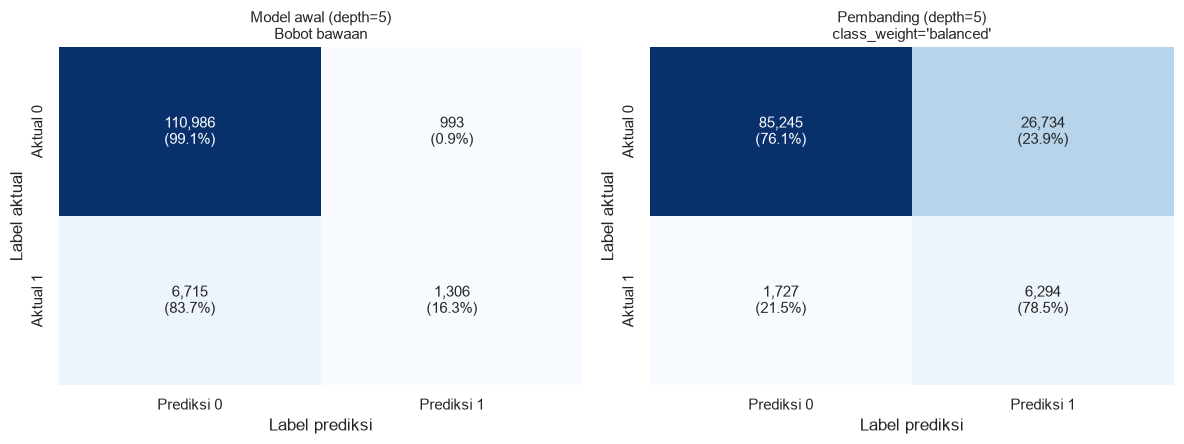

,Model,Total peringatan (TP+FP),Peringatan benar (TP),Peringatan salah (FP),Tunggakan terlewat (FN),Precision (%),Recall (%)
0,"Model awal (depth=5, bobot bawaan)",2299,1306,993,6715,56.81,16.28
1,"Pembanding (depth=5, class_weight='balanced')",33028,6294,26734,1727,19.06,78.47


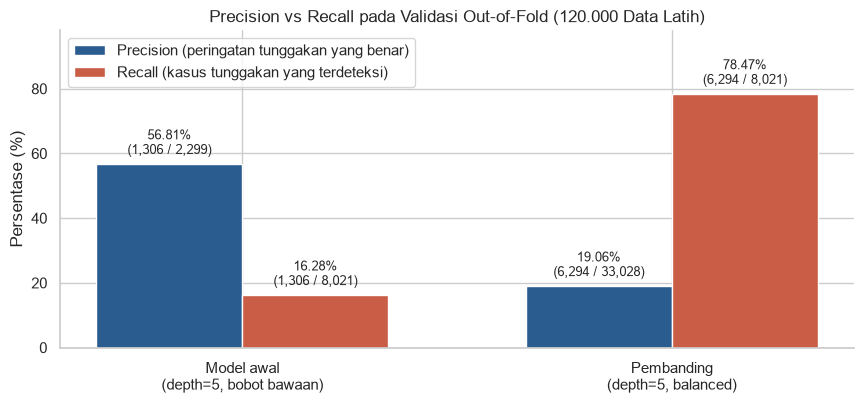

In [8]:
oof_models = [
    (
        "Model awal (depth=5, bobot bawaan)",
        "Model awal (depth=5)\nBobot bawaan",
        DecisionTreeClassifier(max_depth=5, min_samples_leaf=50, random_state=RANDOM_STATE),
    ),
    (
        "Pembanding (depth=5, class_weight='balanced')",
        "Pembanding (depth=5)\nclass_weight='balanced'",
        DecisionTreeClassifier(
            max_depth=5, min_samples_leaf=50, class_weight="balanced", random_state=RANDOM_STATE
        ),
    ),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
cm_records = []

for ax, (label, title, clf) in zip(axes, oof_models):
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", clf),
    ])
    oof_pred = cross_val_predict(pipe, X_train, y_train, cv=cv)
    cm = confusion_matrix(y_train, oof_pred)
    tn, fp, fn, tp = cm.ravel()
    total_alerts = tp + fp
    total_defaults = tp + fn

    cm_records.append({
        "Model": label,
        "Total peringatan (TP+FP)": int(total_alerts),
        "Peringatan benar (TP)": int(tp),
        "Peringatan salah (FP)": int(fp),
        "Tunggakan terlewat (FN)": int(fn),
        "Precision (%)": round(tp / total_alerts * 100, 2),
        "Recall (%)": round(tp / total_defaults * 100, 2),
    })

    row_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    annot = np.array([
        [f"{cm[i, j]:,}\n({row_pct[i, j]:.1f}%)" for j in range(2)]
        for i in range(2)
    ])

    sns.heatmap(
        cm,
        annot=annot,
        fmt="",
        cmap="Blues",
        cbar=False,
        xticklabels=["Prediksi 0", "Prediksi 1"],
        yticklabels=["Aktual 0", "Aktual 1"],
        ax=ax,
        annot_kws={"size": 10.5},
    )
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Label prediksi")
    ax.set_ylabel("Label aktual")

plt.tight_layout()
plt.show()

cm_summary_df = pd.DataFrame(cm_records)
display(cm_summary_df)

# Visualisasi langsung Precision berdampingan dengan Recall
fig, ax = plt.subplots(figsize=(8.8, 4.2))
x = np.arange(len(cm_summary_df))
width = 0.34

bars_prec = ax.bar(
    x - width / 2,
    cm_summary_df["Precision (%)"],
    width,
    color="#2b5c8f",
    label="Precision (peringatan tunggakan yang benar)",
)
bars_rec = ax.bar(
    x + width / 2,
    cm_summary_df["Recall (%)"],
    width,
    color="#c95d45",
    label="Recall (kasus tunggakan yang terdeteksi)",
)

for idx, (bp, br) in enumerate(zip(bars_prec, bars_rec)):
    row = cm_summary_df.iloc[idx]
    ax.text(
        bp.get_x() + bp.get_width() / 2,
        bp.get_height() + 1.8,
        f"{row['Precision (%)']:.2f}%\n({row['Peringatan benar (TP)']:,} / {row['Total peringatan (TP+FP)']:,})",
        ha="center",
        va="bottom",
        fontsize=9.2,
    )
    ax.text(
        br.get_x() + br.get_width() / 2,
        br.get_height() + 1.8,
        f"{row['Recall (%)']:.2f}%\n({row['Peringatan benar (TP)']:,} / 8,021)",
        ha="center",
        va="bottom",
        fontsize=9.2,
    )

ax.set_xticks(x)
ax.set_xticklabels(["Model awal\n(depth=5, bobot bawaan)", "Pembanding\n(depth=5, balanced)"])
ax.set_ylabel("Persentase (%)")
ax.set_ylim(0, 98)
ax.set_title("Precision vs Recall pada Validasi Out-of-Fold (120.000 Data Latih)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### Interpretasi Precision dan Recall terhadap Peringatan Tunggakan

Dari `8.021` kasus tunggakan serius pada `120.000` baris data latih, terlihat kontras yang sangat jelas antara ketepatan peringatan dan cakupan deteksi:
- Model awal (`max_depth=5`, bobot bawaan) mengeluarkan `2.299` peringatan tunggakan; `1.306` di antaranya memang benar-benar menunggak (**Precision `56,81%`**) dan `993` lainnya adalah peminjam lancar (FP). Namun cakupan deteksinya baru `1.306` dari `8.021` kasus (**Recall `16,28%`**), sehingga `6.715` kasus gagal bayar masih terlewat.
- Pembanding `class_weight="balanced"` berhasil mendeteksi jauh lebih banyak kasus, yakni `6.294` dari `8.021` peminjam menunggak (**Recall `78,47%`**) dan menekan kasus terlewat menjadi `1.727`. Untuk mencapai cakupan itu, model mengeluarkan `33.028` peringatan tunggakan, dengan `6.294` peringatan benar dan `26.734` peringatan salah (**Precision `19,06%`**, atau sekitar 1 dari 5 peringatan yang muncul benar-benar berujung tunggakan serius).

Angka ini memberi gambaran konkret untuk tahap pengembangan berikutnya: menaikkan Recall secara langsung menambah beban peringatan palsu, sehingga ambang probabilitas (*threshold tuning*) nantinya perlu disesuaikan dengan kapasitas verifikasi dan toleransi risiko kredit macet (NPL).

## 7. Pengaruh Fitur dan Struktur Pohon Model Awal

Selanjutnya kita melatih `Pipeline` model awal (**Decision Tree `max_depth=5`, `min_samples_leaf=50`, bobot bawaan**) pada seluruh 80% data latih (`X_train`, `y_train`) untuk melihat pengaruh masing-masing fitur serta membaca tiga tingkat keputusan pertama pada pohon. Versi `balanced` tetap ditampilkan berdampingan pada grafik pengaruh fitur sebagai pembanding.

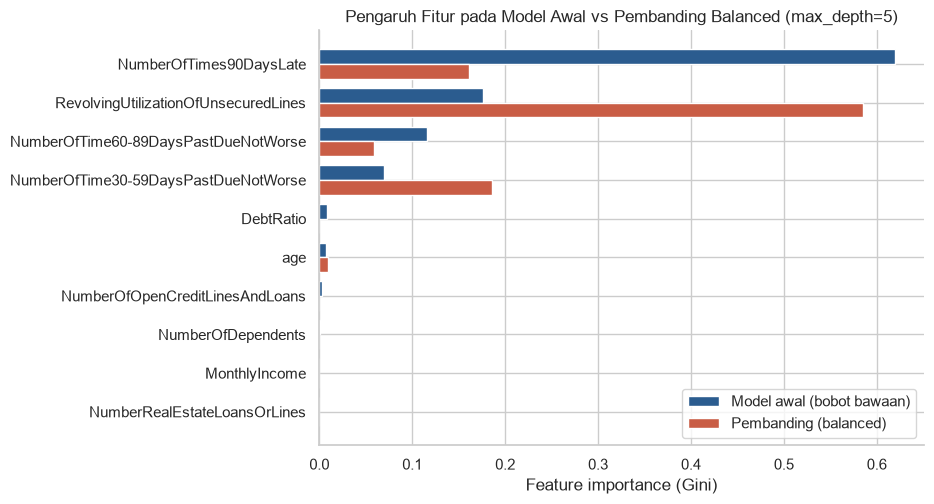

,Model awal (bobot bawaan),Pembanding (balanced)
NumberOfTimes90DaysLate,0.6198,0.1614
RevolvingUtilizationOfUnsecuredLines,0.1757,0.5849
NumberOfTime60-89DaysPastDueNotWorse,0.1157,0.0591
NumberOfTime30-59DaysPastDueNotWorse,0.0698,0.1854
DebtRatio,0.0087,0.0002
age,0.0069,0.0089
NumberOfOpenCreditLinesAndLoans,0.0026,0.0001
NumberOfDependents,0.0008,0.0000
MonthlyIncome,0.0000,0.0000
NumberRealEstateLoansOrLines,0.0000,0.0000


In [9]:
baseline_pipe_default = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=50, random_state=RANDOM_STATE
    )),
])
baseline_pipe_default.fit(X_train, y_train)

baseline_pipe_balanced = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=50,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    )),
])
baseline_pipe_balanced.fit(X_train, y_train)

imp_df = pd.DataFrame({
    "Model awal (bobot bawaan)": baseline_pipe_default.named_steps["model"].feature_importances_,
    "Pembanding (balanced)": baseline_pipe_balanced.named_steps["model"].feature_importances_,
}, index=X_train.columns).sort_values("Model awal (bobot bawaan)", ascending=True)

fig, ax = plt.subplots(figsize=(9.5, 5.2))
y_pos = np.arange(len(imp_df))
height = 0.38
ax.barh(y_pos + height / 2, imp_df["Model awal (bobot bawaan)"], height=height, color="#2b5c8f", label="Model awal (bobot bawaan)")
ax.barh(y_pos - height / 2, imp_df["Pembanding (balanced)"], height=height, color="#c95d45", label="Pembanding (balanced)")
ax.set_yticks(y_pos)
ax.set_yticklabels(imp_df.index)
ax.set_xlabel("Feature importance (Gini)")
ax.set_title("Pengaruh Fitur pada Model Awal vs Pembanding Balanced (max_depth=5)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

display(imp_df.sort_values("Model awal (bobot bawaan)", ascending=False).round(4))

### Analisis Pengaruh Fitur

Pada model awal (bobot bawaan), `NumberOfTimes90DaysLate` menempati posisi paling dominan (`0,6198`), diikuti oleh `RevolvingUtilizationOfUnsecuredLines` (`0,1757`), `NumberOfTime60-89DaysPastDueNotWorse` (`0,1157`), dan `NumberOfTime30-59DaysPastDueNotWorse` (`0,0698`). Keempat fitur riwayat keterlambatan dan pemakaian limit kredit tersebut menyumbang lebih dari `98%` bobot pemecahan pohon, dan pola dominasi yang sama juga terlihat pada pembanding `balanced` (di mana `RevolvingUtilizationOfUnsecuredLines` menjadi yang teratas sebesar `0,5849`).

Sementara itu, `MonthlyIncome` dan `NumberOfDependents` (dua kolom yang diisi dengan median) memiliki kontribusi mendekati `0,0000` pada pohon kedalaman 5 ini. Pada level aturan awal, rekam jejak pembayaran dan tingkat pemakaian kredit jauh lebih menentukan dibanding informasi pendapatan atau jumlah tanggungan.

Berikut visualisasi tiga tingkat pertama dari pohon keputusan **model awal (bobot bawaan)** beserta ringkasan aturan teksnya.

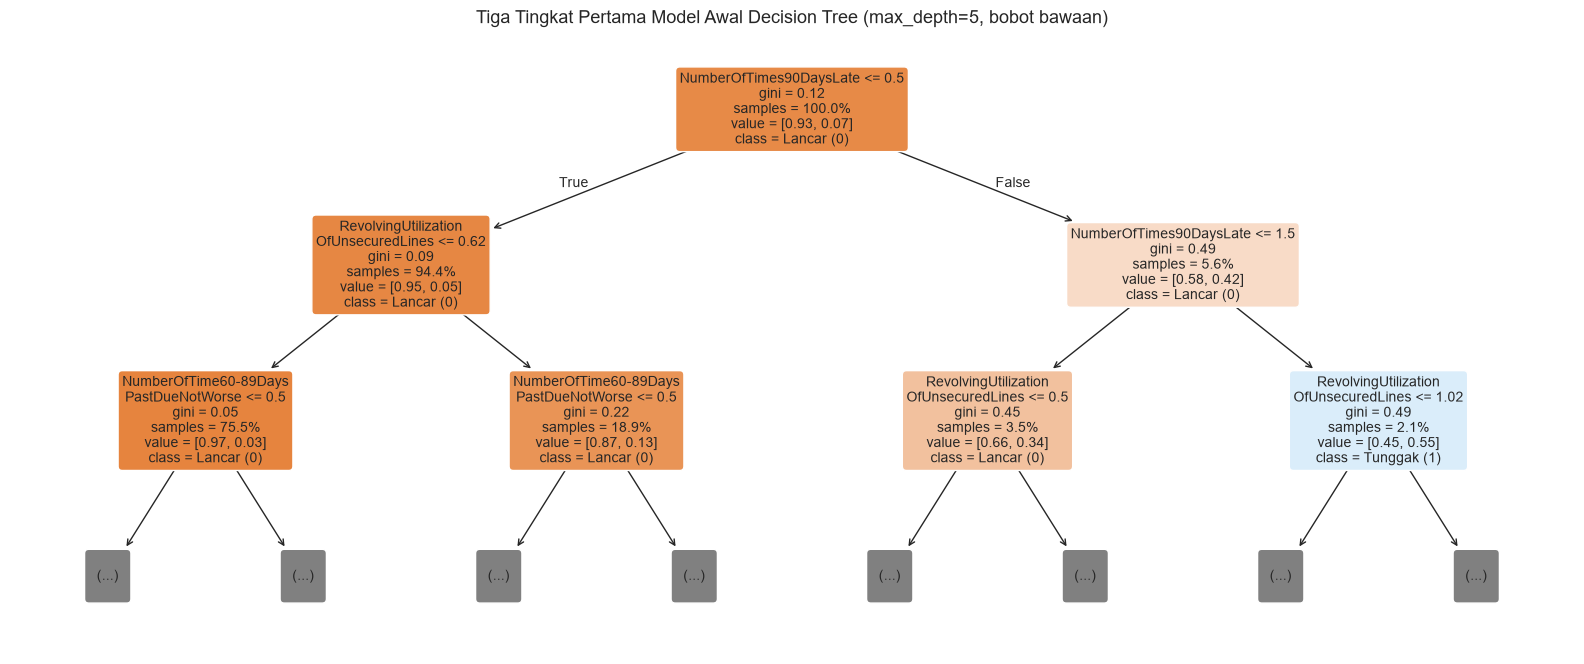

Ringkasan aturan teks model awal (hingga kedalaman 3):
|--- NumberOfTimes90DaysLate <= 0.50
|   |--- RevolvingUtilizationOfUnsecuredLines <= 0.62
|   |   |--- NumberOfTime60-89DaysPastDueNotWorse <= 0.50
|   |   |   |--- NumberOfTime30-59DaysPastDueNotWorse <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- NumberOfTime30-59DaysPastDueNotWorse >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- NumberOfTime60-89DaysPastDueNotWorse >  0.50
|   |   |   |--- NumberOfTime60-89DaysPastDueNotWorse <= 1.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- NumberOfTime60-89DaysPastDueNotWorse >  1.50
|   |   |   |   |--- truncated branch of depth 2
|   |--- RevolvingUtilizationOfUnsecuredLines >  0.62
|   |   |--- NumberOfTime60-89DaysPastDueNotWorse <= 0.50
|   |   |   |--- NumberOfTime30-59DaysPastDueNotWorse <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- NumberOfTime30-59DaysPastDueNotWorse >  0.50
|   |   |

In [10]:
# Bungkus nama fitur yang panjang agar kotak node pada diagram tidak saling menumpuk
wrapped_names = [
    name.replace("RevolvingUtilizationOfUnsecuredLines", "RevolvingUtilization\nOfUnsecuredLines")
        .replace("NumberOfTime30-59DaysPastDueNotWorse", "NumberOfTime30-59Days\nPastDueNotWorse")
        .replace("NumberOfTime60-89DaysPastDueNotWorse", "NumberOfTime60-89Days\nPastDueNotWorse")
        .replace("NumberOfOpenCreditLinesAndLoans", "NumberOfOpenCredit\nLinesAndLoans")
        .replace("NumberRealEstateLoansOrLines", "NumberRealEstate\nLoansOrLines")
    for name in X_train.columns
]

fig, ax = plt.subplots(figsize=(16, 6.8))
plot_tree(
    baseline_pipe_default.named_steps["model"],
    max_depth=2,
    feature_names=wrapped_names,
    class_names=["Lancar (0)", "Tunggak (1)"],
    filled=True,
    rounded=True,
    proportion=True,
    precision=2,
    fontsize=10,
    ax=ax,
)
ax.set_title("Tiga Tingkat Pertama Model Awal Decision Tree (max_depth=5, bobot bawaan)", fontsize=13)
plt.tight_layout()
plt.show()

print("Ringkasan aturan teks model awal (hingga kedalaman 3):")
print(export_text(
    baseline_pipe_default.named_steps["model"],
    feature_names=list(X_train.columns),
    max_depth=3,
))

### Membaca Aturan Model Awal Decision Tree

Struktur tiga tingkat pertama pada model awal mudah dijelaskan ke sisi bisnis:
- Pemecahan paling atas langsung memeriksa apakah peminjam pernah menunggak 90 hari atau lebih sebelumnya (`NumberOfTimes90DaysLate <= 0,50`).
- Pada kelompok yang belum pernah menunggak 90 hari (`94,4%` data latih, proporsi kelas `1` sebesar `5%`), pohon memeriksa pemakaian limit kredit (`RevolvingUtilizationOfUnsecuredLines <= 0,62`), lalu riwayat keterlambatan 60-89 hari dan 30-59 hari.
- Pada kelompok yang sudah pernah menunggak 90 hari (`5,6%` data latih, proporsi label `1` naik menjadi `42%`), pohon memisahkan peminjam yang baru menunggak sekali (`<= 1,50`) dari yang menunggak dua kali atau lebih (`> 1,50`). Pada cabang peminjam yang sudah menunggak dua kali atau lebih (`2,1%` data latih), proporsi label `1` di simpul tersebut berada di sekitar `55%` (lebih besar dari label `0` sebesar `45%`). Namun simpul ini masih berupa cabang antara, bukan keputusan akhir, karena pohon kedalaman 5 masih memiliki pemecahan lanjutan (seperti `RevolvingUtilizationOfUnsecuredLines`, frekuensi keterlambatan lanjutan, dan `DebtRatio`) yang tetap dapat menghasilkan prediksi akhir `0` maupun `1`.

---

## 8. Kesimpulan dan Rencana Tahap Berikutnya

Seluruh tahap praproses awal dan pembangunan model awal telah selesai dijalankan dari awal sampai akhir pada `cs-training.csv`:

1. Kolom `SeriousDlqin2yrs` telah dipisahkan sebagai target dan `Unnamed: 0` dikeluarkan, menyisakan `10` fitur numerik pada `150.000` baris.
2. Pembagian *stratified split* 80:20 (`random_state=42`) menghasilkan `120.000` baris data latih (`8.021` kasus label 1; `6,68%`) dan `30.000` baris data uji akhir (`2.005` kasus label 1; `6,68%`). Bagian `20%` data uji sudah diperiksa jumlah baris, proporsi label, dan nilai kosongnya lalu ditransformasi memakai median dari `X_train` untuk memastikan imputasi bekerja bersih, tetapi belum dipakai untuk memilih model maupun menghitung metrik evaluasi.
3. Imputasi median dipasang melalui `Pipeline` menggunakan `SimpleImputer(strategy="median")` yang hanya di-fit pada data latih (serta dihitung ulang pada setiap fold saat validasi silang). Nilai kosong yang terisi hanya berada pada `MonthlyIncome` (`median = 5.390,0` pada `X_train`) dan `NumberOfDependents` (`median = 0,0`), sementara delapan fitur lainnya sudah lengkap.
4. Model awal yang ditetapkan adalah **Decision Tree dengan `max_depth=5`, `min_samples_leaf=50`, dan bobot bawaan**, dengan hasil validasi silang 5-fold pada 80% data latih:
   - Val ROC-AUC `0,8437` (± `0,0037`) dan PR-AUC `0,3529` (selisih terhadap Train ROC-AUC hanya `0,0019`).
   - Pada validasi *out-of-fold*, model awal menghasilkan Precision `56,81%` (`1.306` dari `2.299` peringatan benar) dan Recall `16,28%` (`1.306` dari `8.021` kasus tunggakan terdeteksi).
5. Hasil pembanding yang disimpan:
   - `DummyClassifier` memperoleh Accuracy `93,32%`, tetapi ROC-AUC `0,5000` serta Precision dan Recall kelas `1` sebesar `0,00%`.
   - Variasi kedalaman pohon menunjukkan pohon tanpa batas (`max_depth=None`) mengalami overfitting berat (Train ROC-AUC `1,0000` vs Val ROC-AUC `0,6120`).
   - Pembanding `class_weight="balanced"` (`max_depth=5`, `min_samples_leaf=50`) menjaga Val ROC-AUC di `0,8441`, menaikkan Recall menjadi `78,47%` (`6.294` dari `8.021` kasus terdeteksi), dengan Precision `19,06%` (`6.294` peringatan benar dari `33.028` total peringatan).

### Rencana Tahap Selanjutnya
- Menguji penanganan anomali yang sudah dicatat pada pemeriksaan awal (kode `96`/`98` pada kolom keterlambatan, baris `age == 0`, serta `609` baris duplikat) dan fitur tambahan seperti indikator kekosongan `MonthlyIncome`.
- Membandingkan model awal ini dengan algoritma lain sesuai panduan proyek (seperti K-NN dengan penskalaan fitur dan Ensemble Learning seperti Random Forest atau Gradient Boosting) pada split dan skema 5-fold CV yang sama.
- Melakukan penyesuaian ambang probabilitas (*threshold tuning*) sebelum menjalankan evaluasi akhir satu kali pada `20%` data uji yang disisihkan.